# Pemodelan Stacking Ensemble — Persepsi Publik terhadap Peluang Kerja Tunarungu


0. **Persiapan** — library dan parameter.
1. **Muat data** + cek bahwa semua komentar lolos filter relevansi.
2. **Finalisasi data** — buang label konflik dan duplikat.
3. **TF-IDF** — ubah teks menjadi angka.
4. **Split data** 80 : 20 (stratified).
5. **Pemodelan** — (A) tuning SVM & XGBoost, (B) baseline tunggal, (C) Stacking: SVM + XGBoost → Logistic Regression.
6. **Evaluasi** pada data uji.
7. **Analisis kesalahan & simpan model** untuk Streamlit.

## Istilah singkat
- **Base learner** (level-0): model dasar (SVM, XGBoost) yang dilatih langsung dari TF-IDF.
- **Meta-learner** (level-1): Logistic Regression yang belajar menggabungkan probabilitas kedua base learner.
- **Out-of-fold (OOF)**: probabilitas yang dibuat dengan model yang *belum pernah melihat* baris itu, supaya meta-learner tidak "mencontek".
- **F1-macro**: rata-rata F1 kedua kelas (adil untuk data tidak seimbang). **F1 eksklusi**: F1 khusus kelas minoritas.


### Sel 1 — Library, parameter, dan pola relevansi
**Apa yang dilakukan:** impor library dan menetapkan semua parameter di satu tempat.
- `RANDOM_STATE = 42` → hasil bisa diulang.
- `TEST_SIZE = 0.20` → 80% data latih, 20% data uji.
- `MIN_DF = 2` → kata yang muncul di < 2 komentar dibuang dari kosakata TF-IDF.
- `N_FOLD = 5` → jumlah lipatan cross-validation (tuning dan stacking).
- `LABEL_COL` → kolom label. **Ganti bila memakai label hasil pelabelan ulang.**
- `POLA_RELEVAN` → **harus sama persis** dengan notebook pra-pemrosesan (dipakai untuk pengaman dan aplikasi Streamlit).

**Cek hasil:** tercetak `Library siap.`

In [19]:
# Library bawaan Python (regex, file, waktu, simpan model, peringatan, unicode)
import re, os, time, joblib, warnings, unicodedata
# numpy/pandas: data | matplotlib: grafik
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
# Pembagian data, cross-validation, pencarian parameter
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
# Model: SVM
from sklearn.svm import SVC
# Model: Logistic Regression (meta-learner)
from sklearn.linear_model import LogisticRegression
# Stacking
from sklearn.ensemble import StackingClassifier
# Metrik evaluasi
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
# Model: XGBoost
from xgboost import XGBClassifier
# Untuk unggah/unduh file di Colab
from google.colab import files

# Sembunyikan peringatan agar output bersih
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)

# PARAMETER: ubah di sini saja
# ===================== PARAMETER (ubah di sini saja) =====================
# Angka acak tetap agar hasil selalu sama
RANDOM_STATE   = 42                      # agar hasil selalu sama (reproducible)
# Folder penyimpanan model (sementara di Colab)
SAVE_DIR       = '/content/model_skripsi'  # folder sementara di Colab (diunduh di Tahap 7)
# Kolom teks bersih
TEXT_COL       = 'clean_text'
# Kolom label (GANTI bila memakai label baru)
LABEL_COL      = 'label_annotator_1'
# Porsi data uji 20%
TEST_SIZE      = 0.20                    # 80 : 20
# Kata harus muncul di minimal 2 komentar
MIN_DF         = 2                       # kata yang muncul < 2 komentar dibuang dari kosakata
# Jumlah lipatan cross-validation
N_FOLD         = 5                       # K-Fold untuk out-of-fold stacking

# Pola relevansi: HARUS SAMA dengan yang dipakai di notebook pra-pemrosesan
# Pola relevansi: HARUS SAMA dengan notebook pra-pemrosesan
POLA_RELEVAN = (
    r'\b(?:tuli|tuna ?rungu|tunarungu|tunawicara|bisu|dongo|difabel|disabel|cacat|penyandang|isyarat|hrd|hasna|hasni|kembar)\b'
    r'|disabilit|wicara|kekurangan|keterbatasan|berkebutuhan|kerja|karyawan|pekerja|pegawai|kesempatan|lowongan|lamar'
    r'|diskriminasi|mandiri|kemampuan|nerima|menerima|diterima|melayani|ramah|sopan|sabar|tabah|prestasi|perusahaan|atasan|bos\b'
)
# =========================================================================
# Buat folder penyimpanan bila belum ada
os.makedirs(SAVE_DIR, exist_ok=True)
print('Library siap.')

Library siap.


## Tahap 1 — Memuat data hasil pra-pemrosesan

### Sel 2 — Unggah data
 membuka dialog unggah; pilih `data_preprocessed.csv` hasil notebook pra-pemrosesan.

In [20]:
print('Pilih file data_preprocessed.csv dari komputer Anda...')
# Munculkan tombol unggah; pilih data_preprocessed.csv
uploaded = files.upload()
nama_file = next(iter(uploaded))
print('File terunggah:', nama_file)

Pilih file data_preprocessed.csv dari komputer Anda...


Saving data_preprocessed (1).csv to data_preprocessed (1).csv
File terunggah: data_preprocessed (1).csv


### Sel 3 — Baca data dan cek distribusi label
 membaca CSV, mencetak ukuran, kolom, nilai kosong, dan proporsi label.
**Cek hasil:** (2934, 3); inklusi 2.117 vs eksklusi 817 (≈ 72 : 28).

In [21]:
# Baca file CSV ke tabel df
df = pd.read_csv(nama_file)
# Ukuran & kolom
print('Ukuran data :', df.shape)
print('Kolom       :', list(df.columns))
# Cek nilai kosong pada kolom teks & label
print('\nMissing value:\n', df[[TEXT_COL, LABEL_COL]].isna().sum())
# Jumlah per label
print('\nDistribusi label:\n', df[LABEL_COL].value_counts())
# Persentase per label
print('\nProporsi:\n', df[LABEL_COL].value_counts(normalize=True).round(3))
# Tampilkan 5 baris pertama
df.head()

Ukuran data : (2934, 3)
Kolom       : ['text', 'clean_text', 'label_annotator_1']

Missing value:
 clean_text           0
label_annotator_1    0
dtype: int64

Distribusi label:
 label_annotator_1
inklusi     2117
eksklusi     817
Name: count, dtype: int64

Proporsi:
 label_annotator_1
inklusi     0.722
eksklusi    0.278
Name: proportion, dtype: float64


,text,clean_text,label_annotator_1
0,dongo,dongo,eksklusi
1,"Maklumi aja,,namanya juga bukan guru disabilitas ,,gk usah dipanjang2kan dn di plintir2kan ntar timbul masalah baru...",maklum nama bukan guru disabilitas tidak usah panjang plintir entar timbul,eksklusi
2,"Bahasa terindah yg ingin ku pelajari, ya bahasa isyarat ❤",bahasa indah ingin ajar bahasa isyarat,inklusi
3,Lah pak supir juga bisu,supir bisu,eksklusi
4,kok kaya boti tapi ramah❤❤😊,kayak bot tapi ramah,eksklusi


### Sel 4 — Pengaman: pastikan semua komentar sudah lolos filter relevansi
 memeriksa apakah tiap komentar memuat kata kunci `POLA_RELEVAN`. Bila > 5% tidak lolos, notebook **berhenti** dengan pesan error.
mencegah Anda tidak sengaja memakai file versi lama (yang belum difilter), yang berisi ±78% komentar tidak relevan.
**Cek hasil:** `Lolos filter relevansi : 2,934 dari 2,934 (100.0%)` dan `OK`.

In [22]:
# Samakan bentuk teks asli (unicode NFKC + huruf kecil) sebelum dicek pola
teks_norm = df['text'].astype(str).map(lambda t: unicodedata.normalize('NFKC', t).lower())
# True bila komentar memuat kata kunci relevansi
lolos = teks_norm.str.contains(POLA_RELEVAN, regex=True)
# Berapa komentar yang lolos
print(f'Lolos filter relevansi : {lolos.sum():,} dari {len(df):,} ({lolos.mean():.1%})')

# Bila > 5% tidak lolos → file salah versi → hentikan
if (~lolos).mean() > 0.05:
    # Hentikan notebook dengan pesan penjelasan
    raise ValueError('Banyak komentar tidak relevan terdeteksi. Jalankan notebook pra-pemrosesan versi terbaru '
                     '(dengan filter relevansi) lalu unggah data_preprocessed.csv yang baru.')
# Bila hanya sedikit yang tidak lolos, biarkan (umumnya beda normalisasi huruf)
elif (~lolos).any():
    print(f'Catatan: {(~lolos).sum()} baris tidak lolos pola (umumnya selisih normalisasi huruf); jumlahnya kecil sehingga dibiarkan.')
else:
    print('OK: seluruh komentar relevan.')

Lolos filter relevansi : 2,934 dari 2,934 (100.0%)
OK: seluruh komentar relevan.


## Tahap 2 — Finalisasi data (cek konflik label & duplikat)

Setelah stemming/normalisasi, beberapa komentar yang berbeda menjadi **teks bersih yang sama** (mis. *"Alamatnya dimana"* dan *"Alamat di mana"* → `alamat mana`).
Jika teks bersih yang sama punya **label berbeda**, model tidak mungkin benar untuk keduanya, dan jika satu masuk data latih dan satu masuk data uji, hasil evaluasi menjadi tidak valid.
Karena itu: (1) baris berkonflik dibuang, (2) duplikat sisanya dijadikan satu, sehingga **setiap `clean_text` unik** dan tidak ada kebocoran antar data latih dan uji.


### Sel 5 — Finalisasi data (konflik label & duplikat)
**Apa yang dilakukan:**
- (a) buang baris tanpa teks,
- (b) buang **semua** baris yang `clean_text`-nya sama tetapi labelnya berbeda,
- (c) hapus duplikat `clean_text` (sisakan satu),
- (d) ubah label menjadi angka: inklusi = 0, eksklusi = 1 (kolom `y`).

 teks yang sama tidak mungkin benar untuk dua label; dan duplikat yang tersebar di data latih + uji membuat skor terlalu bagus.
**Cek hasil:** 2.934 → **2.920** baris (14 baris konflik dibuang); inklusi 2.110, eksklusi 810; rasio ≈ 2,6 : 1.

In [23]:
# Jumlah baris awal (untuk laporan)
n_awal = len(df)

# (a) Buang baris tanpa teks
# (a) Hapus baris tanpa teks
df = df[df[TEXT_COL].notna() & (df[TEXT_COL].str.strip() != '')].copy()

# (b) Konflik label: clean_text sama tetapi label berbeda -> dibuang semua
# (b) Untuk setiap clean_text: berapa label berbeda yang dimilikinya
jml_label = df.groupby(TEXT_COL)[LABEL_COL].nunique()
# clean_text yang punya > 1 label = konflik
teks_konflik = jml_label[jml_label > 1].index
print(f'Teks bersih berkonflik label : {len(teks_konflik)}  ({df[TEXT_COL].isin(teks_konflik).sum()} baris)')
# Buang SEMUA baris berkonflik
df = df[~df[TEXT_COL].isin(teks_konflik)]

# (c) Duplikat clean_text dengan label sama -> sisakan satu
# (c) Hitung duplikat clean_text yang labelnya sama
n_dup = df.duplicated(TEXT_COL).sum()
# Sisakan satu per clean_text → setiap clean_text sekarang unik
df = df.drop_duplicates(TEXT_COL, keep='first').reset_index(drop=True)
print(f'Duplikat clean_text dihapus   : {n_dup}')

# (d) Encoding label
# (d) Pemetaan label teks → angka: inklusi=0, eksklusi=1
LABEL_MAP = {'inklusi': 0, 'eksklusi': 1}
# Buat kolom target y
df['y'] = df[LABEL_COL].map(LABEL_MAP)
# Pengaman: tidak boleh ada label lain selain inklusi/eksklusi
assert df['y'].notna().all(), 'Ada label di luar inklusi/eksklusi! (komentar tidak_relevan harus dibuang di pra-pemrosesan)'
# Ubah ke bilangan bulat
df['y'] = df['y'].astype(int)

# Ringkasan sebelum → sesudah
print(f'\nData: {n_awal} -> {len(df)} baris')
print(df[LABEL_COL].value_counts())
# Rasio kelas (≈ 2,6 : 1 → data tidak seimbang)
print('Rasio inklusi : eksklusi = %.2f : 1' % (df.y.eq(0).sum() / df.y.eq(1).sum()))

Teks bersih berkonflik label : 7  (14 baris)
Duplikat clean_text dihapus   : 0

Data: 2934 -> 2920 baris
label_annotator_1
inklusi     2110
eksklusi     810
Name: count, dtype: int64
Rasio inklusi : eksklusi = 2.60 : 1


## Tahap 3 — Ekstraksi fitur TF-IDF

- **Unigram** (kata tunggal), sesuai proposal.
- `min_df=2`: kata yang hanya muncul di 1 komentar tidak bisa digeneralisasi (±57% kosakata Anda hanya muncul sekali), sehingga hanya menambah dimensi tanpa informasi.
- `sublinear_tf=True`: TF = 1 + log(tf), agar kata yang diulang-ulang dalam satu komentar tidak terlalu mendominasi.
- `norm='l2'` (bawaan): panjang vektor tiap komentar dinormalkan.

### Sel 6 — TF-IDF (teks → angka)
**Apa yang dilakukan:** membuat `TfidfVectorizer` lalu mengubah `clean_text` menjadi matriks `X` (baris = komentar, kolom = kata). Pengaturan:
- `ngram_range=(1,1)` → unigram (kata tunggal), sesuai batasan proposal.
- `min_df=2` → kata yang hanya muncul di 1 komentar diabaikan (tidak bisa digeneralisasi).
- `sublinear_tf=True` → kata yang diulang-ulang tidak terlalu mendominasi.
- `norm='l2'` → panjang vektor tiap komentar disamakan.

**Cek hasil:** matriks **(2920, 1856)** dengan kerapatan ±0,5% (hampir semua nilai 0 = *sparse*, normal untuk teks).


In [24]:
# Siapkan pengubah teks → angka
tfidf = TfidfVectorizer(
    # Unigram saja (kata tunggal), sesuai batasan proposal
    ngram_range=(1, 1),
    # Buang kata yang muncul di < 2 komentar
    min_df=MIN_DF,
    # TF = 1 + log(tf): kata yang diulang tidak mendominasi
    sublinear_tf=True,
    # Normalisasi panjang vektor tiap komentar
    norm='l2',
)
# Pelajari kosakata + hitung bobot, hasilnya matriks sparse X
X = tfidf.fit_transform(df[TEXT_COL])
# Vektor label (0/1)
y = df['y'].values

# Daftar kata (nama kolom matriks X)
kosakata = tfidf.get_feature_names_out()
# Ukuran: (jumlah komentar, jumlah kata unik)
print('Ukuran matriks TF-IDF :', X.shape, '(komentar x kata unik)')
# Persentase sel yang tidak nol (kecil = sparse = normal)
print('Kerapatan (non-zero)  : %.3f%%' % (100 * X.nnz / (X.shape[0] * X.shape[1])))

Ukuran matriks TF-IDF : (2920, 1856) (komentar x kata unik)
Kerapatan (non-zero)  : 0.535%


### Sel 7 — Kata teratas per kelas (gambaran awal)
 menghitung bobot TF-IDF rata-rata tiap kata pada tiap kelas dan menampilkan 10 teratas.
**Cek hasil & cara membaca:** inklusi: *terima, kerja, semoga, kasih, perusahaan*. Eksklusi: *kembar, cantik, hasna, hasni, kdm*.


In [25]:
# 10 kata dengan bobot TF-IDF rata-rata tertinggi pada tiap kelas (gambaran awal fitur)
# Fungsi: rata-rata bobot TF-IDF tiap kata pada komentar di kelas terpilih (m = penanda baris kelas)
rata = lambda m: np.asarray(X[m].mean(axis=0)).ravel()
# Tabel 10 kata teratas per kelas (indeks 0 = inklusi, 1 = eksklusi)
top = pd.DataFrame({
    'inklusi' : kosakata[np.argsort(-rata(y == 0))[:10]],
    'eksklusi': kosakata[np.argsort(-rata(y == 1))[:10]],
})
top

,inklusi,eksklusi
0,matahari,kembar
1,terima,cantik
2,kerja,kerja
3,semoga,tidak
4,kasih,hasna
5,hasni,hasni
6,perusahaan,kdm
7,mereka,tunarungu
8,hasna,bisa
9,orang,matahari


## Tahap 4 — Pembagian data (80 : 20, stratified)

`stratify=y` menjaga proporsi inklusi:eksklusi tetap sama di data latih dan data uji.
Data uji **tidak boleh disentuh** sampai evaluasi akhir (tuning hanya memakai cross-validation pada data latih).

### Sel 8 — Split data latih : uji = 80 : 20 (stratified)
 membagi *indeks* baris dengan `train_test_split(stratify=y)`, lalu mengambil bagian latih dan uji dari matriks `X` dan label `y`. Tabel `ringkas` menampilkan jumlah dan persentase eksklusi di tiap bagian.
 `stratify=y` menjaga proporsi inklusi:eksklusi sama di kedua bagian. Data uji **tidak boleh disentuh** sampai evaluasi akhir (tuning hanya memakai CV pada data latih).

In [26]:
# Daftar nomor baris 0..N-1 (nomor ini nanti dipakai juga untuk analisis kesalahan)
idx = np.arange(len(df))
# Bagi NOMOR baris 80:20; stratify=y menjaga proporsi kelas
idx_tr, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

# Ambil matriks fitur sesuai nomor baris
X_train, X_test = X[idx_tr], X[idx_te]
# Ambil label sesuai nomor baris
y_train, y_test = y[idx_tr], y[idx_te]

# Tabel ringkasan jumlah & % eksklusi di data latih dan uji
ringkas = pd.DataFrame({
    'Jumlah'   : [len(y_train), len(y_test)],
    'Inklusi'  : [(y_train == 0).sum(), (y_test == 0).sum()],
    'Eksklusi' : [(y_train == 1).sum(), (y_test == 1).sum()],
    '% Eksklusi': [round(100 * y_train.mean(), 1), round(100 * y_test.mean(), 1)],
}, index=['Data latih', 'Data uji'])
ringkas

,Jumlah,Inklusi,Eksklusi,% Eksklusi
Data latih,2336,1688,648,27.7
Data uji,584,422,162,27.7


## Tahap 5 — Pemodelan

Kelas tidak seimbang (±70 : 30), jadi:
- SVM dan Logistic Regression memakai `class_weight='balanced'`,
- XGBoost memakai `scale_pos_weight` = jumlah inklusi / jumlah eksklusi pada data latih,
- penilaian tuning memakai **F1-macro** (bukan akurasi, karena akurasi bisa tinggi hanya dengan menebak kelas mayoritas).

### 5A. Tuning hiperparameter base learner (hanya data latih, 5-fold CV)

### Sel 9 (5A) — Tuning hiperparameter base learner
- Membuat 5-fold CV bertingkat (`cv`) dan menghitung `spw` = jumlah inklusi ÷ jumlah eksklusi (≈ 2,6) untuk menyeimbangkan kelas pada XGBoost.
- `GridSearchCV` mencoba semua kombinasi parameter pada **data latih saja**:
  - SVM: kernel `linear`/`rbf` × `C` ∈ {0,5; 1; 5; 10}
  - XGBoost: `n_estimators` ∈ {200, 400} × `max_depth` ∈ {4, 6} × `learning_rate` ∈ {0,05; 0,1}
- Skor penentu **F1-macro** (bukan akurasi, karena akurasi bisa tinggi hanya dengan menebak kelas mayoritas).



In [27]:
# Pembagi 5-fold yang menjaga proporsi kelas di tiap lipatan
cv = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=RANDOM_STATE)
# scale_pos_weight XGBoost = inklusi ÷ eksklusi → menaikkan bobot kelas eksklusi
spw = (y_train == 0).sum() / (y_train == 1).sum()      # scale_pos_weight XGBoost
# Cetak nilainya
print('scale_pos_weight XGBoost = %.2f' % spw)

# TUNING SVM
# ---------- SVM ----------
# Catat waktu mulai
t0 = time.time()
# Coba semua kombinasi parameter SVM dengan 5-fold CV
gs_svm = GridSearchCV(
    # class_weight='balanced': kelas minoritas diberi bobot lebih
    SVC(class_weight='balanced', random_state=RANDOM_STATE),
    # Kandidat: kernel × C (C besar = margin lebih ketat)
    param_grid={'kernel': ['linear', 'rbf'], 'C': [0.5, 1, 5, 10]},
    # Penilaian = F1-macro (adil untuk kelas tidak seimbang)
    scoring='f1_macro', cv=cv, n_jobs=-1, verbose=0)
# Jalankan pencarian pada DATA LATIH saja
gs_svm.fit(X_train, y_train)
# Parameter terbaik + skor CV
print(f'SVM     terbaik: {gs_svm.best_params_} | F1-macro CV = {gs_svm.best_score_:.4f} ({time.time()-t0:.0f} dtk)')

# TUNING XGBOOST
# ---------- XGBoost ----------
# Catat waktu mulai (XGBoost lebih lama)
t0 = time.time()
# Coba kombinasi parameter XGBoost
gs_xgb = GridSearchCV(
    # scale_pos_weight menangani ketidakseimbangan; tree_method='hist' = cepat
    XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', tree_method='hist',
                  random_state=RANDOM_STATE, n_jobs=-1),
    # Kandidat: jumlah pohon × kedalaman × learning rate
    param_grid={'n_estimators': [200, 400], 'max_depth': [4, 6],
                'learning_rate': [0.05, 0.1], 'subsample': [0.8], 'colsample_bytree': [0.8]},
    # Penilaian sama: F1-macro
    scoring='f1_macro', cv=cv, n_jobs=1, verbose=0)
# Jalankan pencarian pada DATA LATIH saja
gs_xgb.fit(X_train, y_train)
# Parameter terbaik + skor CV
print(f'XGBoost terbaik: {gs_xgb.best_params_} | F1-macro CV = {gs_xgb.best_score_:.4f} ({time.time()-t0:.0f} dtk)')

scale_pos_weight XGBoost = 2.60
SVM     terbaik: {'C': 1, 'kernel': 'rbf'} | F1-macro CV = 0.7681 (21 dtk)
XGBoost terbaik: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 400, 'subsample': 0.8} | F1-macro CV = 0.7385 (70 dtk)


### 5B. Model baseline (SVM tunggal & XGBoost tunggal)
Dipakai sebagai pembanding terhadap Stacking Ensemble (sesuai Bab 3.2.6 proposal).
`probability=True` pada SVM agar menghasilkan probabilitas (dipakai Level-1 pada stacking).

### Sel 10 (5B) — Latih model baseline
melatih SVM tunggal dan XGBoost tunggal dengan parameter terbaik dari sel sebelumnya pada seluruh data latih. keduanya menjadi **pembanding** untuk membuktikan apakah Stacking benar-benar lebih baik`probability=True` pada SVM agar menghasilkan probabilitas yang nantinya diumpankan ke meta-learner.

In [28]:
# Parameter akhir SVM = hasil tuning + class_weight + probability=True
svm_params = {**gs_svm.best_params_, 'class_weight': 'balanced', 'probability': True, 'random_state': RANDOM_STATE}
# Parameter akhir XGBoost = hasil tuning + pengaturan keseimbangan kelas
xgb_params = {**gs_xgb.best_params_, 'scale_pos_weight': spw, 'eval_metric': 'logloss',
              'tree_method': 'hist', 'random_state': RANDOM_STATE, 'n_jobs': -1}

# Latih SVM tunggal pada seluruh data latih
svm_model = SVC(**svm_params).fit(X_train, y_train)
# Latih XGBoost tunggal pada seluruh data latih
xgb_model = XGBClassifier(**xgb_params).fit(X_train, y_train)
# Konfirmasi selesai
print('Baseline SVM & XGBoost selesai dilatih.')

Baseline SVM & XGBoost selesai dilatih.


### 5C. Stacking Ensemble
- **Level-0 (base learner):** SVM dan XGBoost.
- **Level-1 (meta-learner):** Logistic Regression.
- Meta-learner dilatih dari **prediksi out-of-fold** (`cv=5`), sehingga tidak menerima prediksi dari model yang sudah melihat baris yang sama (mencegah overfitting pada level-1).
- `stack_method='predict_proba'` memakai probabilitas, bukan label keras.

### Sel 11 (5C) — Stacking Ensemble
 membangun `StackingClassifier`:
- **Level-0:** SVM + XGBoost (parameter terbaik).
- **Level-1:** Logistic Regression (`class_weight='balanced'`).
- `cv=5` → input meta-learner adalah probabilitas **out-of-fold**, sehingga tidak ada kebocoran data.
- `stack_method='predict_proba'` → memakai probabilitas, bukan label keras.
- `passthrough=False` → meta-learner hanya melihat probabilitas base learner, bukan fitur TF-IDF asli.

Setelah dilatih, dicetak **koefisien** meta-learner = seberapa besar tiap base learner dipercaya.


In [29]:
# Rakit Stacking Ensemble
stacking = StackingClassifier(
    # LEVEL-0: dua base learner (SVM & XGBoost)
    estimators=[('svm', SVC(**svm_params)),
                ('xgb', XGBClassifier(**xgb_params))],
    # LEVEL-1: Logistic Regression sebagai meta-learner
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    # Meta-learner menerima probabilitas, bukan label keras
    stack_method='predict_proba',
    # Probabilitas OUT-OF-FOLD (5-fold) untuk melatih meta-learner → mencegah kebocoran
    cv=StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=RANDOM_STATE),
    # Jalankan berurutan (lebih stabil); passthrough=False = fitur TF-IDF asli tidak diberikan ke meta-learner
    n_jobs=1, passthrough=False)

# Catat waktu mulai
t0 = time.time()
# Latih (base learner dilatih ulang pada seluruh data latih setelah OOF dibuat)
stacking.fit(X_train, y_train)
# Waktu pelatihan
print(f'Stacking selesai dilatih ({time.time()-t0:.0f} dtk)')

# Koefisien meta-learner: makin besar = makin dipercaya
# Bobot kontribusi tiap base learner pada meta-learner
# Ambil koefisien (urutan: SVM, XGBoost)
koef = stacking.final_estimator_.coef_.ravel()
print('\nKoefisien Logistic Regression (meta-learner):')
# Cetak koefisien per base learner
for n, k in zip(['SVM', 'XGBoost'], koef):
    print(f'  {n:8s}: {k:+.3f}')

Stacking selesai dilatih (26 dtk)

Koefisien Logistic Regression (meta-learner):
  SVM     : +3.999
  XGBoost : +1.570


## Tahap 6 — Evaluasi pada data uji
Metrik: akurasi, presisi, recall, F1 (rata-rata macro dan khusus kelas eksklusi).

### Sel 12 — Evaluasi ketiga model pada data uji
 memprediksi data uji dengan SVM, XGBoost, dan Stacking, lalu menghitung akurasi, presisi, recall, F1 (macro) dan F1 kelas eksklusi. Juga mencetak **patokan** akurasi bila selalu menebak kelas mayoritas.
**Cara membaca:** model dianggap bermanfaat bila akurasinya jauh di atas patokan (≈ 0,723) dan F1-macro tinggi.


In [30]:
# Tiga model yang akan dibandingkan
daftar_model = {'SVM (baseline)': svm_model, 'XGBoost (baseline)': xgb_model, 'Stacking Ensemble': stacking}

# Wadah hasil metrik & prediksi
hasil, prediksi = [], {}
# Untuk tiap model: prediksi DATA UJI lalu hitung metrik
for nama, m in daftar_model.items():
    p = m.predict(X_test); prediksi[nama] = p
    hasil.append({
        'Model'             : nama,
        # Akurasi = porsi prediksi benar
        'Akurasi'           : accuracy_score(y_test, p),
        # Presisi: ketepatan prediksi (rata-rata kedua kelas)
        'Presisi (macro)'   : precision_score(y_test, p, average='macro'),
        # Recall: kemampuan menemukan semua data tiap kelas (rata-rata kedua kelas)
        'Recall (macro)'    : recall_score(y_test, p, average='macro'),
        # F1: rata-rata harmonik presisi & recall (rata-rata kedua kelas)
        'F1 (macro)'        : f1_score(y_test, p, average='macro'),
        # F1 khusus kelas eksklusi (kelas minoritas / 'positif')
        'F1 eksklusi'       : f1_score(y_test, p, pos_label=1),
    })
# Susun tabel perbandingan
tabel = pd.DataFrame(hasil).set_index('Model').round(4)

# Patokan: akurasi bila model selalu menebak kelas mayoritas
# Patokan: tebak selalu kelas mayoritas
# Hitung patokan
mayoritas = max(y_test.mean(), 1 - y_test.mean())
# Cetak patokan
print(f'Patokan akurasi bila selalu menebak kelas mayoritas = {mayoritas:.4f}')
# Tampilkan tabel hasil
tabel

Patokan akurasi bila selalu menebak kelas mayoritas = 0.7226


,Akurasi,Presisi (macro),Recall (macro),F1 (macro),F1 eksklusi
Model,,,,,
SVM (baseline),0.8288,0.7854,0.8036,0.7933,0.7076
XGBoost (baseline),0.8082,0.7610,0.7741,0.7668,0.6686
Stacking Ensemble,0.8288,0.7878,0.8264,0.8010,0.7268


### Sel 13 — Confusion matrix dan laporan klasifikasi
**Apa yang dilakukan:** menggambar confusion matrix ketiga model dan mencetak laporan klasifikasi (presisi, recall, F1 per kelas) untuk Stacking.
**Cara membaca:** diagonal = prediksi benar. Kotak kiri-bawah/kanan-atas = kesalahan.
**Cek hasil:** eksklusi recall 0,82 tetapi presisi hanya 0,65 → model cenderung **terlalu sering menebak eksklusi** (akibat `class_weight='balanced'`).

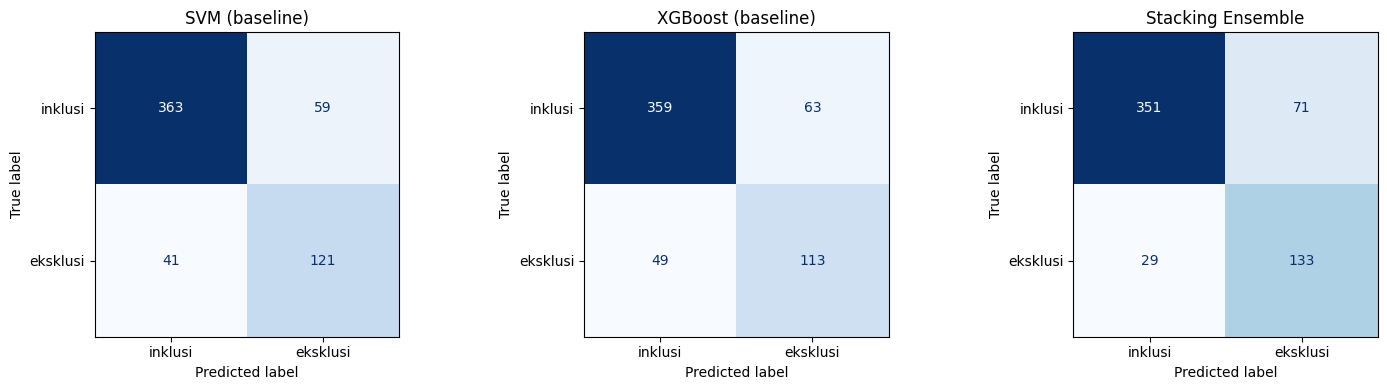

Laporan klasifikasi — Stacking Ensemble
              precision    recall  f1-score   support

     inklusi     0.9237    0.8318    0.8753       422
    eksklusi     0.6520    0.8210    0.7268       162

    accuracy                         0.8288       584
   macro avg     0.7878    0.8264    0.8010       584
weighted avg     0.8483    0.8288    0.8341       584



In [31]:
# Tiga panel gambar berdampingan
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# Gambar confusion matrix untuk tiap model
for ax, (nama, p) in zip(axes, prediksi.items()):
    # Baris = label asli, kolom = prediksi
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=['inklusi', 'eksklusi']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nama)
# Rapikan lalu tampilkan
plt.tight_layout(); plt.show()

# Laporan lengkap per kelas untuk Stacking
print('Laporan klasifikasi — Stacking Ensemble')
# Presisi / recall / F1 per kelas
print(classification_report(y_test, prediksi['Stacking Ensemble'], target_names=['inklusi', 'eksklusi'], digits=4))

### Sel 14 — Grafik perbandingan model
**Apa yang dilakukan:** diagram batang akurasi, F1-macro, dan F1 eksklusi tiap model; garis putus-putus = patokan kelas mayoritas.
**Mengapa:** gambar siap pakai untuk Bab 4.

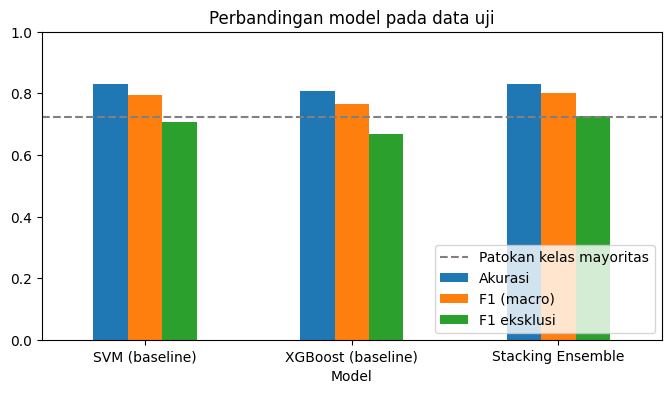

In [32]:
# Diagram batang metrik utama
tabel[['Akurasi', 'F1 (macro)', 'F1 eksklusi']].plot(kind='bar', figsize=(8, 4), rot=0)
# Garis putus-putus = patokan kelas mayoritas
plt.axhline(mayoritas, color='gray', ls='--', label='Patokan kelas mayoritas')
plt.ylim(0, 1); plt.title('Perbandingan model pada data uji'); plt.legend(loc='lower right'); plt.show()

## Tahap 7 — Analisis kesalahan & penyimpanan model

### Sel 15 — Analisis kesalahan prediksi
 mengambil data uji yang salah diprediksi Stacking dan menampilkan 15 contoh acak.


In [33]:
# Ambil data uji yang salah diprediksi (untuk pembahasan & cek kualitas label)
# Contoh komentar yang salah diprediksi oleh Stacking (berguna untuk pembahasan & cek kualitas label)
# Potong data asli sesuai nomor baris data uji
df_uji = df.iloc[idx_te].copy()
# Tambah kolom prediksi Stacking
df_uji['prediksi'] = np.where(prediksi['Stacking Ensemble'] == 1, 'eksklusi', 'inklusi')
# Baris yang prediksinya ≠ label asli
salah = df_uji[df_uji['prediksi'] != df_uji[LABEL_COL]]
# Jumlah & persentase salah
print(f'Salah prediksi: {len(salah)} dari {len(df_uji)} ({len(salah)/len(df_uji):.1%})')
# 15 contoh acak: baca apakah salahnya di model atau di label
salah[['text', TEXT_COL, LABEL_COL, 'prediksi']].sample(min(15, len(salah)), random_state=RANDOM_STATE)

Salah prediksi: 100 dari 584 (17.1%)


,text,clean_text,label_annotator_1,prediksi
278,Andaisaja beliou datang ke banjar ke pelosok banyak sangat membutuhkan beliou seperti saysh yang tsk pernah di perha...,andaisaja beliou banjar pelosok butuh beliou saysh tsk perhati pemerintah rumah tidak layak huni kalou hujan bocor t...,inklusi,eksklusi
810,"seratus ribu di banding satu ,disabilitas yg di beri kesempatan dan itu sudah cukup mengangkat citra pemerintah 😂",ratus ribu banding disabilitas kesempatan cukup angkat citra pemerintah,eksklusi,inklusi
319,Matahari bayar pajak ke negara.. \nYang rusakin toko online rumah.. Toko online bayar pajak ga ya. .. \nSemenjak or...,matahari bayar pajak negara rusakin toko online rumah toko online bayar pajak tidak semenjak orang toko online baja ...,inklusi,eksklusi
814,Utamakan etos kerja untuk bersaing. Jgn ada diskriminasi ttg fisik atau umur,utama etos kerja saing jangan diskriminasi fisik umur,inklusi,eksklusi
237,Teh HASNI mawa barokah kanggo toko na 🤲🤲🤲🤲🤲,teh hasni mawa barokah kanggo toko,inklusi,eksklusi
402,Nitip pada karyawan karyawan nya jangan di galakin😊,nitip karyawan karyawan jangan galakin,eksklusi,inklusi
1108,Respect buat manajee matahari❤tapi dua cewek kembar ini sumpah cantik banget😍,respect manajee matahari tapi cewek kembar sumpah cantik banget,inklusi,eksklusi
1406,"Kenapa yang kaya gini cantik-cantik ya, saya punya ponakan juga cantik sekarang kerja dipabrik sampe bisa nyekolahin...",kenapa kayak cantik cantik ponakan cantik kerja pabrik bisa nyekolahin adik luar biasa perusahaan terima kekurangan ...,inklusi,eksklusi
2640,yutub nya KDM gubernur jabar juga ada hasna dan hasni dan dua temannya juga tunarungu di matahari dep. store bandung...,yutub kdm gubernur jabar hasna hasni teman tunarungu matahari dep store bandung viral kdm kunjung matahari barang be...,eksklusi,inklusi
2861,TUNARUNGU KASIHAN. DIA MAXIM 😢,tunarungu kasihan maxim,inklusi,eksklusi
